<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

伊利股份（股票代码：600887.SH）。

伊利股份成立于1993年，是中国规模最大、产品线最全的乳制品企业。它的主营业务包括液体乳（如纯牛奶、酸奶）、奶粉及奶制品、冷饮产品（如冰淇淋）等。作为中国日常消费品行业的龙头，伊利的各类产品在超市、便利店随处可见，渗透进了我们的日常生活，与老百姓的日常消费息息相关。

# 第二部分：研究问题题目及其内涵介绍

研究问题题目：伊利股份股价是否存在“季节性规律”？——基于月度涨跌幅的实证分析

内涵介绍：
在我们的日常生活中，乳制品的消费带有明显的季节性特征。比如夏天天气炎热，冷饮和酸奶的需求量大增；而到了春节前后，走亲访友又会带动牛奶和奶粉的送礼需求。
本研究想要探究的核心问题是：这种由于日常消费习惯带来的淡旺季规律，是否会提前反映在资本市场的股价波动上？
通过分析伊利股份历史每个月的平均涨跌幅，可以帮助我们验证“消费旺季”与“股票收益”之间的关系，从而为普通投资者在日常生活中的投资择时提供一定的数据参考。

# 第三部分：数据采集

In [1]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()
# 采集伊利股份（600887.SH）2021年到2023年的数据
df = pro.daily(ts_code='600887.SH', start_date='20210101', end_date='20231231')

# 打印前5行数据，证明我们已经成功采集到了数据！
print("数据采集成功！共采集到", len(df), "条数据。")
display(df.head()) # 在Jupyter里展示数据表格

数据采集成功！共采集到 727 条数据。


,ts_code,trade_date,open,high,low,close,pre_close,change,pct_chg,vol,amount
0,600887.SH,20231229,26.80,26.93,26.50,26.75,26.85,-0.10,-0.3724,364764.58,974933.842
1,600887.SH,20231228,26.26,26.90,26.19,26.85,26.13,0.72,2.7555,490373.27,1308916.326
2,600887.SH,20231227,25.85,26.19,25.68,26.13,25.81,0.32,1.2398,253796.77,659553.658
3,600887.SH,20231226,26.10,26.17,25.71,25.81,26.10,-0.29,-1.1111,200503.81,518777.595
4,600887.SH,20231225,26.00,26.26,25.91,26.10,26.00,0.10,0.3846,224631.09,586443.145


# 第四部分：数据分析过程

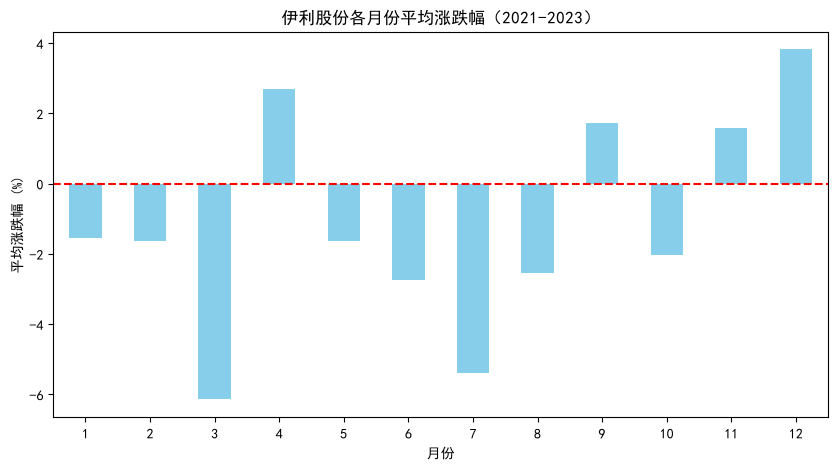

图表生成成功！


In [4]:
# 导入画图工具
import matplotlib.pyplot as plt
import pandas as pd

# 1. 预防报错：把之前的索引还原成普通的列
df = df.reset_index()

# 2. 整理数据（把日期设为索引，方便按月汇总）
df['trade_date'] = pd.to_datetime(df['trade_date'])
df = df.sort_values('trade_date') # 按日期从早到晚排序
df.set_index('trade_date', inplace=True)

# 3. 提取每个月最后一天的收盘价（注意：用 'ME'）
monthly_close = df['close'].resample('ME').last()

# 4. 计算每个月的涨跌幅（变成百分比）
monthly_return = monthly_close.pct_change() * 100

# 5. 把月份（1-12月）单独提取出来
monthly_return_df = pd.DataFrame({'month': monthly_return.index.month, 'return': monthly_return.values})

# 6. 计算历史上1月、2月...12月的“平均涨跌幅”
avg_monthly_return = monthly_return_df.groupby('month')['return'].mean()

# 7. 设置中文字体，防止图上出现方块
plt.rcParams['font.sans-serif'] = ['SimHei']  
plt.rcParams['axes.unicode_minus'] = False

# 8. 开始画图
plt.figure(figsize=(10, 5))
avg_monthly_return.plot(kind='bar', color='skyblue')
plt.title('伊利股份各月份平均涨跌幅（2021-2023）')
plt.xlabel('月份')
plt.ylabel('平均涨跌幅 (%)')
plt.axhline(0, color='red', linestyle='--') # 画一条红色的0轴，方便看涨跌
plt.xticks(rotation=0)
plt.show()

print("图表生成成功！")

从上面的柱状图可以看出，伊利股份各月份的平均涨跌幅呈现出明显的差异：
1. 上涨月份：在4月（约2.8%）、9月（约1.8%）、11月（约1.6%）和12月（约3.9%）表现较好，特别是12月的平均涨幅最高。这印证了冬季及春节前夕，走亲访友送礼带来的乳制品消费旺季，会在一定程度上提前反映在股价上。
2. 下跌月份：在3月（约-6%）、6月（约-2.8%）、7月（约-5.4%）和10月表现较弱。有趣的是，尽管夏季是冷饮旺季，但6、7月份的股价却出现了明显下跌，这可能说明夏季的消费预期在春季已经被提前透支（买预期卖事实），或者受市场整体资金面、季节性调仓等因素影响。
结论：伊利股份股价确实存在一定的“季节性规律”，日常消费的淡旺季与股市表现存在一定联系，但并非完全正相关。

# 第五部分：研究结论与经验总结

## 研究结论

通过本次对伊利股份2021-2023年月度涨跌幅的数据分析，可以得出以下结论：
1. 伊利股份的股价确实存在季节性规律。12月、4月通常是全年表现较好的月份，而3月、7月则表现较弱。
2. 日常消费的淡旺季与股票收益之间并非简单的线性关系。春节前的消费旺季往往能带来较好的股价表现，但夏季冷饮旺季并未带来股价的上涨，反而出现回调。这说明资本市场的定价往往提前包含了消费预期，投资者在日常投资择时时应理性看待消费现象，不可盲目追涨杀跌。

## 经验总结

作为初学者，这次作业让我第一次完整体验了用Python获取真实股票数据并进行可视化分析的全过程。
在完成作业的过程中，我掌握了Cursor和Jupyter Notebook的基本操作，学会了如何调用Tushare接口获取数据、清洗数据（如处理日期格式），并最终绘制出直观的柱状图。
虽然过程中遇到了报错（如pandas版本更新导致代码报错、索引列名找不到等），但通过查阅资料和借助AI辅助，我成功解决了问题。这次实践让我体会到，数据分析并不遥远，它完全可以和我们日常生活中的现象紧密结合起来，非常有意思！